# ДЗ 1. Рекомендательные системы

In [2]:
import os
from pathlib import Path

os.environ['MPLCONFIGDIR'] = str(Path.cwd() / '.cache/matplotlib')
os.environ['OMP_NUM_THREADS'] = '2'
os.environ['OPENBLAS_NUM_THREADS'] = '2'

import gc
import itertools
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display
from threadpoolctl import threadpool_limits

from models import ItemKNN, IALS, EASE, FactorizationMachine, CustomTargetALS
from models.utils import load_data, chronological_split, seen_matrix, evaluate

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)
torch.use_deterministic_algorithms(True)
pd.set_option('display.max_colwidth', None)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

Matplotlib is building the font cache; this may take a moment.


## Данные

Будем использовать датасет [Amazon Baby, 2014](https://mcauleylab.ucsd.edu/public_datasets/data/amazon/links.html). Возьмём готовую 5-core выборку целиком

В [файле отзывов](https://mcauleylab.ucsd.edu/public_datasets/data/amazon/categoryFiles/reviews_Baby_5.json.gz)
`reviewerID` — пользователь, `asin` — товар, `overall` — оценка от 1 до 5,
`unixReviewTime` — время отзыва. Из [метаданных](https://mcauleylab.ucsd.edu/public_datasets/data/amazon/categoryFiles/meta_Baby.json.gz)
возьмём название, категорию и бренд товара.

Релевантным будем считать товар с отложенной оценкой не ниже 4.
А рекомендовать буду 10 товаров, которых ещё нет в истории отзывов пользователя

## Подготовка и EDA

Сначала проверим пропуски, повторы и корректность оценок и дат. Строки без ID,
оценки или времени удалим. Если на одну пару пользователь–товар приходится
несколько отзывов, оставим самый ранний

In [3]:
raw, clean, metadata, data_report = load_data()
display(pd.Series(data_report))
display(clean.head())

raw_interactions                                                              160792
clean_interactions                                                            160792
users                                                                          19445
items                                                                           7050
missing_by_field           {'user_id': 0, 'item_id': 0, 'rating': 0, 'timestamp': 0}
duplicate_pairs                                                                    0
invalid_or_missing_rows                                                            0
metadata_source_rows                                                           71317
metadata_items_matched                                                          7050
sparsity                                                                    0.998827
dtype: object

,user_id,item_id,rating,timestamp
0,API5JLBRT6FIN,B00000IZQI,5.0,982454400
1,AQCHVXD1R9WYI,B000056HM8,4.0,995328000
2,AQCHVXD1R9WYI,B000056JHX,5.0,995328000
3,AQCHVXD1R9WYI,B000056OUH,5.0,995846400
4,AQCHVXD1R9WYI,B000056W4X,5.0,995846400


Видим, что после чистки объём не изменился, т.е. в основных полях нет пропусков и повторных пар пользователь–товар

In [4]:
activity = clean.groupby('user_id').size()
popularity = clean.groupby('item_id').size()
display(pd.DataFrame({'user_interactions': activity.describe(), 'item_interactions': popularity.describe()}))
display(pd.DataFrame({'missing': raw.isna().sum(), 'fraction': raw.isna().mean()}))
item_metadata = pd.DataFrame({'item_id': np.sort(clean.item_id.unique())}).merge(metadata, on='item_id', how='left')
metadata_coverage = pd.DataFrame({
    'nonempty_fraction': {c: item_metadata[c].fillna('').ne('').mean() for c in ['title', 'brand']},
})
metadata_coverage.loc['category', 'nonempty_fraction'] = item_metadata.category.fillna('UNKNOWN').ne('UNKNOWN').mean()
display(metadata_coverage)
display(item_metadata.groupby('category', dropna=False).size().sort_values(ascending=False).head(12).rename('items').to_frame())
top_count = max(1, int(np.ceil(len(popularity) * .01)))
print(f'Разреженность: {data_report["sparsity"]:.4%}')
print(f'Доля отзывов у верхнего 1% товаров: {popularity.nlargest(top_count).sum()/len(clean):.2%}')
print(f'Доля оценок от 4: {clean.rating.ge(4).mean():.2%}')

,user_interactions,item_interactions
count,19445.000000,7050.000000
mean,8.269067,22.807376
std,5.436152,36.764476
min,5.000000,5.000000
25%,5.000000,7.000000
50%,6.000000,11.000000
75%,9.000000,23.000000
max,125.000000,780.000000


,missing,fraction
user_id,0,0.0
item_id,0,0.0
rating,0,0.0
timestamp,0,0.0


,nonempty_fraction
title,0.998156
brand,0.698298
category,1.000000


,items
category,
Baby,7050


Разреженность: 99.8827%
Доля отзывов у верхнего 1% товаров: 12.04%
Доля оценок от 4: 78.69%


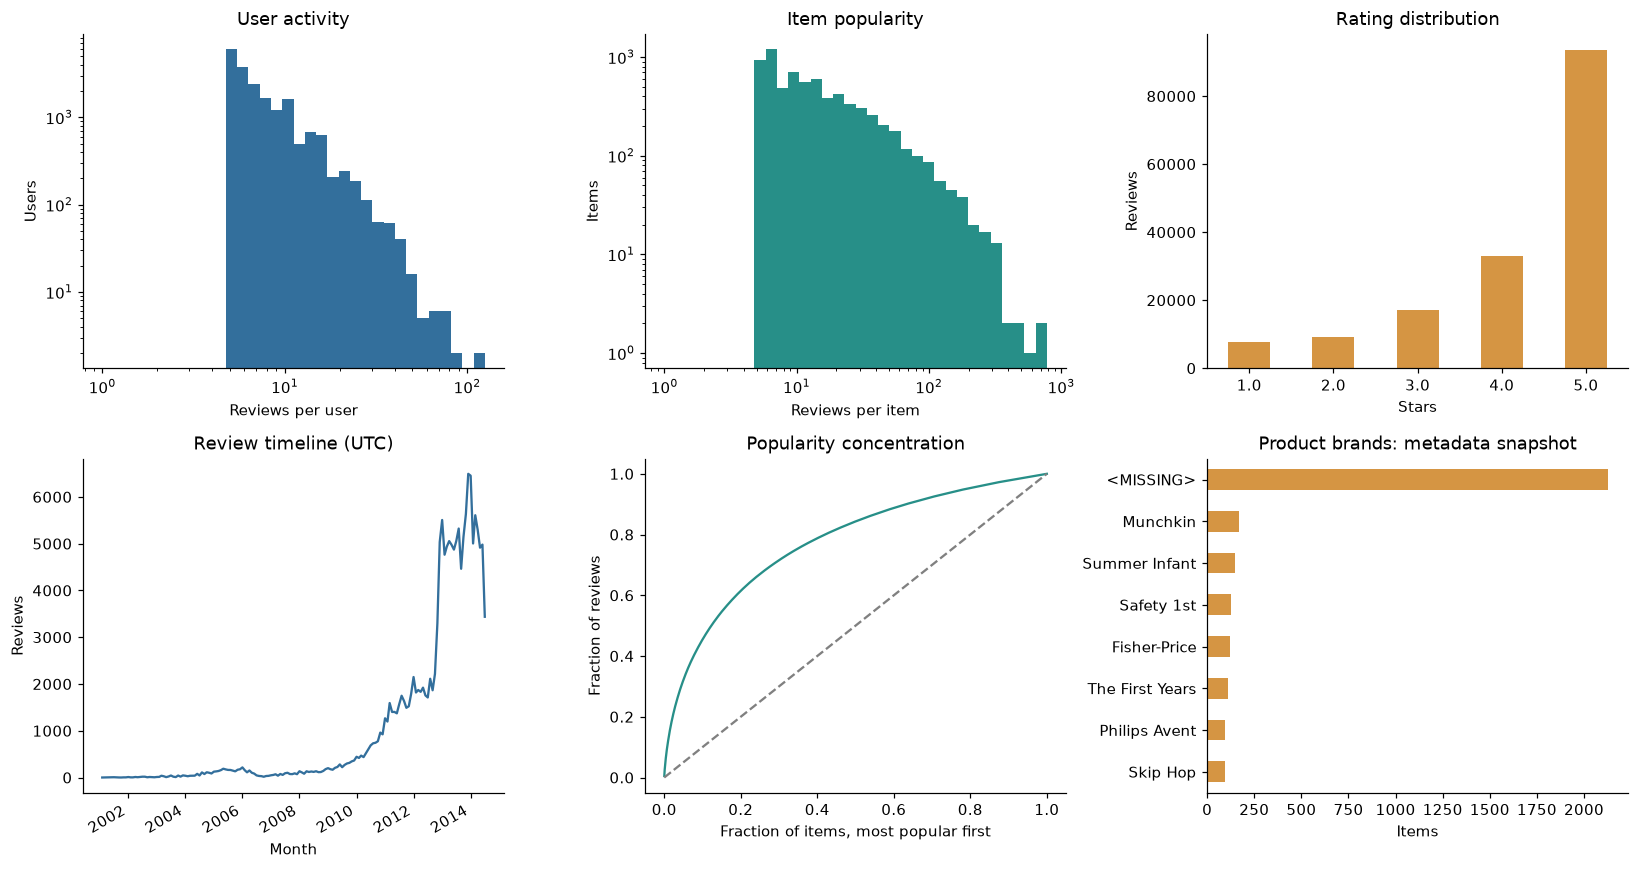

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes[0,0].hist(activity, bins=np.geomspace(1, max(activity.max(), 2), 35), color='#336f9c')
axes[0,0].set(xscale='log', yscale='log', title='User activity', xlabel='Reviews per user', ylabel='Users')
axes[0,1].hist(popularity, bins=np.geomspace(1, max(popularity.max(), 2), 35), color='#278f88')
axes[0,1].set(xscale='log', yscale='log', title='Item popularity', xlabel='Reviews per item', ylabel='Items')
clean.rating.value_counts().sort_index().plot.bar(ax=axes[0,2], color='#d59543', rot=0)
axes[0,2].set(title='Rating distribution', xlabel='Stars', ylabel='Reviews')
monthly = clean.groupby(pd.to_datetime(clean.timestamp, unit='s', utc=True).dt.tz_localize(None).dt.to_period('M')).size()
monthly.index = monthly.index.to_timestamp()
monthly.plot(ax=axes[1,0], color='#336f9c')
axes[1,0].set(title='Review timeline (UTC)', xlabel='Month', ylabel='Reviews')
concentration = np.sort(popularity.to_numpy())[::-1].cumsum() / len(clean)
axes[1,1].plot(np.arange(1,len(concentration)+1)/len(concentration), concentration, color='#278f88')
axes[1,1].plot([0,1],[0,1], '--', color='gray')
axes[1,1].set(title='Popularity concentration', xlabel='Fraction of items, most popular first', ylabel='Fraction of reviews')
brands = item_metadata.brand.fillna('').replace('', '<MISSING>')
brands.value_counts().head(8).sort_values().plot.barh(ax=axes[1,2], color='#d59543')
axes[1,2].set(title='Product brands: metadata snapshot', xlabel='Items', ylabel='')
fig.tight_layout()
plt.show()

По графикам видим, что у большинства пользователей короткая история,
а популярность товаров распределена неравномерно. Разреженность составляет 99,88%.
У всех товаров одна категория Baby, названия почти везде заполнены, а бренд указан примерно у 70% товаров

## Разбиение и метрики

Разделим данные по времени: первые 80% возьмём для train, следующие 10% для
validation, остаток - test. Отзывы с одинаковым временем оставим в одной
части. Словари пользователей и товаров построим по train. Новых пользователей
и товары при оценке пропустим и отдельно посчитаем, сколько отзывов из-за этого потеряли.

Ранжировать будем весь каталог из train, убрав уже известные пользователю товары,
в том числе с низкими оценками. На validation учтём историю из train, а перед
test добавим к ней validation. Возьмём пользователей, у которых есть хотя бы один
положительный отзыв в train и хотя бы один релевантный товар в отложенной части.
Для всех моделей используем одних и тех же пользователей, кандидатов и правила исключения.

Подбирать параметры будем по **NDCG@10**: эта метрика учитывает, насколько высоко
в списке оказался релевантный товар. Ещё посчитаем **Recall@10**, т.е. какую долю
релевантных товаров удалось найти. Обе метрики усредним по пользователям,
$R_u$ - множество релевантных товаров пользователя

$$\mathrm{NDCG@10}_u=\frac{\sum_{j=1}^{10}\mathbf1[i_j\in R_u]/\log_2(j+1)}
{\sum_{j=1}^{\min(10,|R_u|)}1/\log_2(j+1)},\qquad
\mathrm{Recall@10}_u=\frac{|\mathrm{Top10}_u\cap R_u|}{|R_u|}$$

In [5]:
split = chronological_split(clean)
display(pd.DataFrame({s: split['report'][s] for s in ['train','validation','test']}).T)
display(pd.Series({
    'train_before_UTC': str(pd.to_datetime(split['t1'], unit='s', utc=True)),
    'validation_before_UTC': str(pd.to_datetime(split['t2'], unit='s', utc=True)),
    'train_catalog_items': split['shape'][1], 'train_users': split['shape'][0],
    'validation_evaluation_users': len(split['validation_users']), 'test_evaluation_users': len(split['test_users'])
}))
assert split['train'].timestamp.max() < split['t1'] < split['t2']

,raw_rows,warm_rows,cold_user_rows,cold_item_rows,removed_rows_union,positive_rows
train,128595,128595,0,0,0,101086
validation,15983,10221,5271,571,5762,8004
test,16214,7879,6897,1642,8335,6130


train_before_UTC               2014-01-16 00:00:00+00:00
validation_before_UTC          2014-04-15 00:00:00+00:00
train_catalog_items                                 6875
train_users                                        17730
validation_evaluation_users                         3256
test_evaluation_users                               2578
dtype: object

Получились границы 16 января и 15 апреля 2014 года. 
Из 16 214 test-отзывов 8 335 исключены из-за новых пользователей или товаров

## Модели

Попробуем пять моделей. Дальше $X_{ui}=1$, если есть отзыв с оценкой от 4,
иначе 0. Через $\Omega$ обозначим все наблюдавшиеся пары пользователь–товар.

**ItemKNN.** Для каждого товара найдём L похожих товаров. Сходство посчитаем
по косинусу бинарных столбцов и уменьшим его для пар с небольшим пересечением:
$$s_{ij}=\frac{X_i^TX_j}{\|X_i\|\|X_j\|}\frac{n_{ij}}{n_{ij}+\beta},\quad n_{ij}=X_i^TX_j.$$
Диагональ занулим. Рекомендации получим, сложив сходства с товарами из положительной
истории пользователя: итоговые оценки равны $XS$.

**iALS.** Подберём факторы пользователей и товаров, минимизируя ошибку:
$$\sum_{ui}c_{ui}(p_{ui}-a_u^Tb_i)^2+\lambda(\|A\|_F^2+\|B\|_F^2),\quad
p_{ui}=X_{ui},\quad c_{ui}=1+\alpha\mathbf1[(u,i)\in\Omega].$$
Будем по очереди обновлять факторы пользвателей и товаров через нормальные
уравнения. Для отзывов на 1–3 таргет равен нулю, но confidence выше, чем у пары без отзыва.

**EASE.** Попробуем восстановить историю пользователя через линейные связи между товарами:
$$\min_W\|X-XW\|_F^2+\lambda\|W\|_F^2,\quad W_{ii}=0.$$
Для этого найдём $P=(X^TX+\lambda I)^{-1}$ и положим $W_{ij}=-P_{ij}/P_{jj}$
при $i\ne j$. Диагональ оставим нулевой, итоговые оценки получим как $XW$.

**FM.** Здесь кроме ID добавим признаки пользователей и товаров. Предсказание
факторизационной машины второго порядка:
$$f(x)=w_0+\sum_jw_jx_j+\frac12\sum_f\left[(\sum_jv_{jf}x_j)^2-\sum_jv_{jf}^2x_j^2\right].$$
Возьмём активность и среднюю оценку пользователя, популярность и среднюю оценку
товара, время с первого отзыва о товаре. Значения разобьём на интервалы.
Эти признаки могут помочь учесть объём истории, привычку ставить оценки и давность
товара. Посчитаем их только по истории, доступной к моменту рекомендации.
Названия и категории не будем брать в обучение: у их снимка нет дат изменений.

Обучать будем с logistic loss и L2 с помощью Adam. На каждый положительный отзыв
добавим три случайных товара, которых нет в доступной истории пользователя.
Проверим также вариант только с ID, чтобы понять, помогли ли доп. признаки

**ALS с кастомным таргетом.** В детских товарах потребности могут меняться со временем,
поэтому попробуем сильнее учитывать недавние оценки. Confidence и обновления ALS
оставим прежними, а таргет зададим так:
$$p^*_{ui}=\frac{r_{ui}-3}{2}\left[\frac12+\frac12\exp\left(-\log2\frac{t_c-t_{ui}}{86400h}\right)\right]$$
Для пар без отзыва он равен нулю. Здесь $t_c$ момент рекомендации, h - период
полураспада в днях

## Подбор гиперпараметров

Теперь переберём параметры из сеток ниже. Для каждой модели оставим вариант
с наибольшим NDCG@10 на validation, а при равенстве возьмём первый. К test вернёмся после выбора настроек.

In [6]:
MODELS = {'ItemKNN': ItemKNN, 'IALS': IALS, 'EASE': EASE,
          'FM': FactorizationMachine, 'CustomTargetALS': CustomTargetALS}
GRIDS = {'ItemKNN': {'neighbors': [50, 150], 'shrinkage': [5.0, 25.0]},
 'IALS': {'factors': [24, 48],
          'regularization': [1.0, 10.0],
          'alpha': [20.0],
          'iterations': [12],
          'seed': [42]},
 'EASE': {'regularization': [20.0, 100.0, 500.0]},
 'FM': {'factors': [24, 48],
        'regularization': [1e-06, 1e-05],
        'learning_rate': [0.01],
        'epochs': [12],
        'negatives': [3],
        'seed': [42],
        'metadata': [True]},
 'CustomTargetALS': {'factors': [24, 48],
                     'regularization': [1.0, 10.0],
                     'alpha': [20.0],
                     'iterations': [12],
                     'half_life_days': [90.0, 365.0],
                     'seed': [42]}}

In [7]:
validation_rows = []
selected = {}
train_seen = seen_matrix(split['train'], split['shape'])

for name, grid in GRIDS.items():
    best_score = -np.inf
    keys = list(grid)
    for values in itertools.product(*(grid[key] for key in keys)):
        params = dict(zip(keys, values))
        with threadpool_limits(limits=2):
            model = MODELS[name](**params).fit(split['train'], split['shape'], cutoff=split['t1'])
            metrics = evaluate(model, split['validation'], split['validation_users'], train_seen)
        validation_rows.append({'model': name, **metrics, 'parameters': params})
        if metrics['NDCG@10'] > best_score:
            best_score = metrics['NDCG@10']
            selected[name] = params.copy()
        del model
        gc.collect()
    print(f'{name}: лучшая validation NDCG@10 = {best_score:.5f}', flush=True)

validation_results = pd.DataFrame(validation_rows)
display(validation_results)
display(pd.DataFrame([{'model': name, **params} for name, params in selected.items()]))

ItemKNN: лучшая validation NDCG@10 = 0.01238


IALS: лучшая validation NDCG@10 = 0.01351


EASE: лучшая validation NDCG@10 = 0.01405


FM: лучшая validation NDCG@10 = 0.01497


CustomTargetALS: лучшая validation NDCG@10 = 0.01917


,model,NDCG@10,Recall@10,parameters
0,ItemKNN,0.010815,0.017434,"{'neighbors': 50, 'shrinkage': 5.0}"
1,ItemKNN,0.012375,0.020098,"{'neighbors': 50, 'shrinkage': 25.0}"
2,ItemKNN,0.010849,0.017455,"{'neighbors': 150, 'shrinkage': 5.0}"
3,ItemKNN,0.012311,0.019573,"{'neighbors': 150, 'shrinkage': 25.0}"
4,IALS,0.012887,0.019937,"{'factors': 24, 'regularization': 1.0, 'alpha': 20.0, 'iterations': 12, 'seed': 42}"
5,IALS,0.013506,0.020887,"{'factors': 24, 'regularization': 10.0, 'alpha': 20.0, 'iterations': 12, 'seed': 42}"
6,IALS,0.011430,0.018955,"{'factors': 48, 'regularization': 1.0, 'alpha': 20.0, 'iterations': 12, 'seed': 42}"
7,IALS,0.011055,0.017558,"{'factors': 48, 'regularization': 10.0, 'alpha': 20.0, 'iterations': 12, 'seed': 42}"
8,EASE,0.012307,0.018568,{'regularization': 20.0}
9,EASE,0.013343,0.019856,{'regularization': 100.0}


,model,neighbors,shrinkage,factors,regularization,alpha,iterations,seed,learning_rate,epochs,negatives,metadata,half_life_days
0,ItemKNN,50.0,25.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,IALS,NaN,NaN,24.0,10.00000,20.0,12.0,42.0,NaN,NaN,NaN,NaN,NaN
2,EASE,NaN,NaN,NaN,500.00000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,FM,NaN,NaN,48.0,0.00001,NaN,NaN,42.0,0.01,12.0,3.0,True,NaN
4,CustomTargetALS,NaN,NaN,24.0,10.00000,20.0,12.0,42.0,NaN,NaN,NaN,NaN,90.0


На validation вперёд вышел ALS с кастомным таргетом: NDCG@10 = 0,01917.
У обычного iALS получилось 0,01351. 

Но посмотрим, сохранится ли преимущество на test:

## Test

Возьмём выбранные настройки и заново обучим модели на train + validation.
Каталог оставим тем же, из train, а затем сравним результаты на test

In [8]:
fit_history = pd.concat([split['train'], split['validation']], ignore_index=True)
test_seen = seen_matrix(fit_history, split['shape'])
jobs = [(name, MODELS[name], params) for name, params in selected.items()]
jobs.append(('FM_ID_only', FactorizationMachine, dict(selected['FM'], metadata=False)))
test_rows = []

for name, model_class, params in jobs:
    started = time.perf_counter()
    with threadpool_limits(limits=2):
        model = model_class(**params).fit(fit_history, split['shape'], cutoff=split['t2'])
        metrics = evaluate(model, split['test'], split['test_users'], test_seen)
    tuned = {key: value for key, value in params.items()
             if key in GRIDS.get(name, {}) and len(GRIDS[name][key]) > 1}
    test_rows.append({'model': name, **metrics, 'parameters': tuned})
    print(f'{name}: {time.perf_counter() - started:.1f} с', flush=True)
    del model
    gc.collect()

test_results = pd.DataFrame(test_rows)
main_results = test_results[test_results.model.ne('FM_ID_only')].sort_values('NDCG@10', ascending=False)
display(main_results.reset_index(drop=True))
display(test_results[test_results.model.isin(['FM', 'FM_ID_only'])][['model', 'NDCG@10', 'Recall@10']])

ItemKNN: 1.8 с


IALS: 9.7 с


EASE: 9.1 с


FM: 24.1 с


CustomTargetALS: 8.4 с


FM_ID_only: 15.5 с


,model,NDCG@10,Recall@10,parameters
0,EASE,0.013059,0.019252,{'regularization': 500.0}
1,ItemKNN,0.012426,0.018394,"{'neighbors': 50, 'shrinkage': 25.0}"
2,CustomTargetALS,0.011003,0.019216,"{'factors': 24, 'regularization': 10.0, 'half_life_days': 90.0}"
3,IALS,0.010377,0.016030,"{'factors': 24, 'regularization': 10.0}"
4,FM,0.008936,0.017668,"{'factors': 48, 'regularization': 1e-05}"


,model,NDCG@10,Recall@10
3,FM,0.008936,0.017668
5,FM_ID_only,0.011277,0.020325


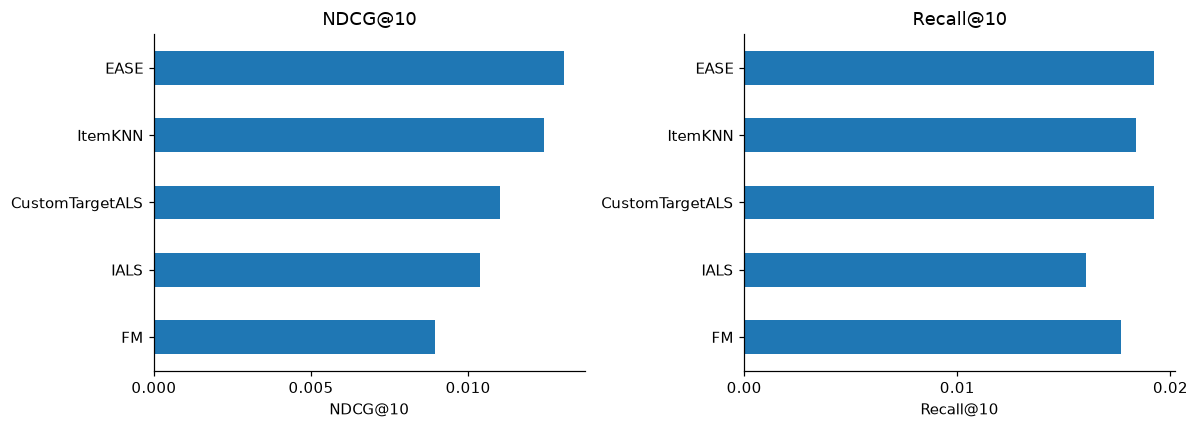

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axes, ['NDCG@10', 'Recall@10']):
    main_results.set_index('model')[metric].plot.barh(ax=ax)
    ax.invert_yaxis()
    ax.locator_params(axis='x', nbins=4)
    ax.set(title=metric, xlabel=metric, ylabel='')
fig.tight_layout()
plt.show()

## Выводы

Лучше всего показал себя EASE с λ=500: NDCG@10 = 0,01306,
Recall@10 = 0,01925. Следом идёт ItemKNN с 50 соседями

У обеих ALS выбраны 24 фактора, λ=10 и α=20. С кастомным таргетом и h=90 дней
получилось 0,01100 по NDCG@10, с обычным — 0,01038. Прирост маленький и до EASE обе модели не дотянули. Лидерство кастомной модели на val не сохранилось на следующем временном периоде.

Дополнительные признаки FM в этом эксперименте не помогли: NDCG@10 снизился
с 0,01128 у варианта только с ID до 0,00894 у модели с метапризнаками.

Но по отсутствию отзыва нельзя понять, интересен ли товар пользователю, поэтому результаты на показах или покупках могут отличаться